# Module 11 — L'apprentissage contrastif

> **Objectif** : apprendre des représentations (de phrases, de séquences, d'images…) **sans étiquettes**, ou avec des étiquettes faibles, en rapprochant des paires « positives » et en éloignant les « négatives ». On dérive la perte **InfoNCE** et son gradient, on l'entraîne de zéro en NumPy sur un problème où l'on voit l'espace s'organiser, on étudie le rôle de la **température**, de la **taille du batch**, de l'**alignement** et de l'**uniformité**, puis on passe à **SimCSE** et `sentence-transformers` pour les embeddings de phrases, et aux usages en biologie.

| | |
|---|---|
| **Durée estimée** | 3 h |
| **Prérequis** | Modules 0, 3 (word2vec), 6, 7 (embeddings de phrases) |
| **Librairies** | `numpy`, `matplotlib`, `scikit-learn` ; `torch`, `transformers`, `sentence-transformers` (sections 7–8) |

**Plan**

1. L'idée : apprendre une géométrie à partir de paires
2. De word2vec à InfoNCE
3. La perte InfoNCE : maths, gradient, lien avec l'information mutuelle
4. Un encodeur contrastif de zéro (NumPy)
5. La température : sélectionner les négatifs difficiles
6. Alignement, uniformité et taille du batch
7. SimCSE : des embeddings de phrases par contraste
8. `sentence-transformers`, négatifs difficiles et évaluation
9. En biologie : séquences, paires et modalités
10. Récapitulatif et exercices

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
rng = np.random.default_rng(0)


def softmax(z, axis=-1):
    z = z - z.max(axis=axis, keepdims=True); e = np.exp(z); return e / e.sum(axis=axis, keepdims=True)

## 1. L'idée : apprendre une géométrie à partir de paires

### 💡 Intuition

On ne dit pas au modèle **ce qu'est** chaque exemple ; on lui dit seulement **quelles paires se ressemblent**. Deux vues d'une même phrase (deux traductions, une paraphrase, la même phrase avec un dropout différent), deux séquences homologues, une image et sa légende : ce sont des **positifs**. Tout le reste du batch sert de **négatifs**. Le modèle apprend un encodeur $f$ tel que :

- les positifs soient **proches** dans l'espace d'embedding (**alignement**) ;
- l'ensemble des embeddings soit **bien réparti** sur la sphère, pour garder un maximum d'information (**uniformité**).

Ce que le modèle considère comme « identique » est entièrement défini par **le choix des positifs** : c'est là que se loge la connaissance du domaine. Si deux vues diffèrent par la couleur d'une image, le modèle apprend à ignorer la couleur ; si elles diffèrent par un dropout, il apprend une représentation robuste au bruit ; si elles sont deux traductions, il apprend à ignorer la langue.

| Méthode | Positifs | Négatifs |
|---|---|---|
| word2vec (module 3) | mot et voisin de contexte | mots tirés au hasard |
| SimCLR (images) | deux augmentations de la même image | les autres images du batch |
| SimCSE non supervisé | la même phrase, deux dropouts | les autres phrases du batch |
| SimCSE supervisé | phrase et phrase **impliquée** (NLI) | contradictions (négatifs difficiles) + batch |
| CLIP | image et sa légende | les autres légendes du batch |
| Recherche dense (DPR) | question et passage pertinent | passages non pertinents (BM25) + batch |

## 2. De word2vec à InfoNCE

word2vec avec échantillonnage négatif (module 3) était déjà contrastif : **classification binaire** de chaque paire (vraie ou bruit). InfoNCE (van den Oord et al., 2018) en est la version **multiclasse** : parmi $N$ candidats, dont un seul positif, **lequel** est le bon ? C'est une classification à $N$ classes par softmax, où les « classes » sont les autres exemples du batch.

Pour une ancre $q$, son positif $k^+$ et $N-1$ négatifs $k_j^-$, avec une similarité $\mathrm{sim}(u,v) = \frac{u^\top v}{\lVert u\rVert\lVert v\rVert}$ et une température $\tau$ :
$$
\boxed{\ \mathcal L_{\text{InfoNCE}} = -\log\frac{\exp(\mathrm{sim}(q, k^+)/\tau)}{\exp(\mathrm{sim}(q, k^+)/\tau) + \sum_{j}\exp(\mathrm{sim}(q, k_j^-)/\tau)}\ }
$$

**L'astuce des négatifs « dans le batch »** : on calcule $2B$ embeddings ($B$ paires), la matrice $S\in\mathbb R^{B\times B}$ de toutes les similarités, et la perte est une **entropie croisée dont la bonne classe de la ligne $i$ est la colonne $i$** :
$$
S_{ij} = \frac{z_i^\top z'_j}{\tau},\qquad \mathcal L = \frac{1}{B}\sum_i -\log\mathrm{softmax}(S_{i,:})_i
$$
Chaque positif sert gratuitement de négatif pour les $B-1$ autres ancres. La version **symétrique** (CLIP) moyenne les pertes par lignes et par colonnes.

## 3. La perte InfoNCE : maths, gradient, information mutuelle

### 📐 Le gradient

C'est la softmax + entropie croisée du module 0 : par rapport aux logits,
$$
\frac{\partial\mathcal L_i}{\partial S_{ij}} = P_{ij} - \mathbb 1[i=j],\qquad P = \mathrm{softmax}(S)\ \text{par ligne}
$$
Puis, avec $S_{ij} = z_i^\top z'_j/\tau$ :
$$
\frac{\partial\mathcal L_i}{\partial z_i} = \frac{1}{\tau}\Big(\underbrace{\sum_j P_{ij}\,z'_j}_{\text{moyenne pondérée des candidats}} - \underbrace{z'_i}_{\text{positif}}\Big)
$$
**Lecture** : l'ancre est **attirée** par son positif et **repoussée** par chaque négatif proportionnellement à $P_{ij}$, la probabilité que le modèle le confonde avec le positif. Les négatifs déjà lointains ($P_{ij}\approx 0$) ne comptent plus : l'effort se concentre automatiquement sur les **négatifs difficiles**.

**La normalisation L2** ($z = u/\lVert u\rVert$) ajoute un facteur : $\frac{\partial z}{\partial u} = \frac{1}{\lVert u\rVert}(I - zz^\top)$. Le gradient est projeté sur le plan tangent à la sphère : seule la **direction** compte, pas la norme.

### 📐 Le lien avec l'information mutuelle

van den Oord et al. montrent que, pour $N$ candidats,
$$
I(q; k^+) \ \ge\ \log N - \mathcal L_{\text{InfoNCE}}
$$
Minimiser InfoNCE maximise une **borne inférieure** de l'information mutuelle entre les deux vues. Conséquences :
- la borne est plafonnée à $\log N$ : **plus de négatifs** (grands batchs) permettent d'apprendre plus d'information, d'où les batchs de 4 096 à 32 768 de SimCLR et CLIP, et les files de négatifs de MoCo ;
- la perte d'un modèle qui devine au hasard vaut $\log N$ (repère utile, comme $\log K$ au module 0).

> ⚠️ Poole et al. (2019) et Tschannen et al. (2020) ont montré que cette lecture « maximisation de l'information mutuelle » n'explique pas à elle seule les bonnes représentations : la **géométrie** induite (alignement, uniformité) et le **choix des augmentations** comptent davantage. On y revient en section 6.

## 4. Un encodeur contrastif de zéro (NumPy)

### Le problème-jouet

On génère des données de dimension 32 où l'information utile (une **classe latente** parmi 10, qu'on ne montrera jamais au modèle) vit dans 8 dimensions, et 24 dimensions de **nuisance** à forte variance (un « style » qui change tout le temps) dominent tout.

Les **vues** (augmentations) d'un même exemple partagent le signal mais ont une nuisance **retirée à neuf**, plus un peu de bruit et un masquage aléatoire de 10 % des coordonnées. Le modèle ne voit que des paires de vues. S'il apprend à rapprocher les deux vues d'un même exemple, il doit apprendre à **ignorer la nuisance**, et donc, sans le savoir, à révéler les classes.

In [2]:
n, d_sig, d_nuis, n_cls = 3000, 8, 24, 10
protos = rng.normal(0, 1.0, (n_cls, d_sig))
y_lat = rng.integers(0, n_cls, n)
signal = protos[y_lat] + rng.normal(0, 0.35, (n, d_sig))
d_in = d_sig + d_nuis


def view(signal, r, nuis_std=2.0, noise=0.1, p_mask=0.1):
    """One augmentation: same signal (+ small noise), fresh nuisance, random masking."""
    x = np.concatenate([signal + r.normal(0, noise, signal.shape), r.normal(0, nuis_std, (len(signal), d_nuis))], axis=1)
    return x * (r.random(x.shape) > p_mask)

X_raw = view(signal, np.random.default_rng(1))
print(f"{n} points, {d_in} dims ({d_sig} signal + {d_nuis} nuisance), {n_cls} hidden classes")
print("variance explained by signal dims:", round(X_raw[:, :d_sig].var(0).sum() / X_raw.var(0).sum(), 3))

3000 points, 32 dims (8 signal + 24 nuisance), 10 hidden classes
variance explained by signal dims: 0.077


### L'encodeur et la perte

Encodeur linéaire $u = Wx\in\mathbb R^{16}$, puis normalisation $z = u/\lVert u\rVert$. Perte InfoNCE symétrique sur des batchs de paires. Tous les gradients sont ceux de la section 3.

In [3]:
def encode(W, X):
    U = X @ W.T
    norms = np.linalg.norm(U, axis=1, keepdims=True) + 1e-12
    return U / norms, U, norms


def info_nce_grads(W, X1, X2, tau):
    Z1, U1, n1 = encode(W, X1); Z2, U2, n2 = encode(W, X2)
    B = len(X1)
    S = Z1 @ Z2.T / tau                                         # (B, B) similarity logits
    P_r, P_c = softmax(S, axis=1), softmax(S, axis=0)           # rows: z1 -> z2 ; columns: z2 -> z1
    idx = np.arange(B)
    loss = -0.5 * (np.log(P_r[idx, idx]).mean() + np.log(P_c[idx, idx]).mean())
    dS = 0.5 * ((P_r - np.eye(B)) + (P_c - np.eye(B))) / B     # symmetric CE gradient wrt S
    dZ1, dZ2 = dS @ Z2 / tau, dS.T @ Z1 / tau
    dU1 = (dZ1 - Z1 * (Z1 * dZ1).sum(1, keepdims=True)) / n1    # through the L2 normalization
    dU2 = (dZ2 - Z2 * (Z2 * dZ2).sum(1, keepdims=True)) / n2
    return loss, dU1.T @ X1 + dU2.T @ X2                         # dW


# finite-difference check
W_chk = rng.normal(size=(4, d_in)) * 0.1
Xa, Xb = view(signal[:16], rng), view(signal[:16], rng)
_, G = info_nce_grads(W_chk, Xa, Xb, 0.2)
eps, num = 1e-6, np.zeros_like(W_chk)
for i in range(W_chk.shape[0]):
    for j in range(W_chk.shape[1]):
        Wp, Wm = W_chk.copy(), W_chk.copy(); Wp[i, j] += eps; Wm[i, j] -= eps
        num[i, j] = (info_nce_grads(Wp, Xa, Xb, 0.2)[0] - info_nce_grads(Wm, Xa, Xb, 0.2)[0]) / (2 * eps)
print("relative gradient error:", np.linalg.norm(G - num) / np.linalg.norm(G + num))

relative gradient error: 1.5116531983595715e-10


In [4]:
class Adam:
    def __init__(self, params, lr=1e-2, b1=0.9, b2=0.999, eps=1e-8):
        self.p, self.lr, self.b1, self.b2, self.eps = params, lr, b1, b2, eps
        self.m = [np.zeros_like(x) for x in params]; self.v = [np.zeros_like(x) for x in params]; self.t = 0
    def step(self, grads):
        self.t += 1
        for p, g, m, v in zip(self.p, grads, self.m, self.v):
            m *= self.b1; m += (1 - self.b1) * g
            v *= self.b2; v += (1 - self.b2) * g * g
            p -= self.lr * (m / (1 - self.b1 ** self.t)) / (np.sqrt(v / (1 - self.b2 ** self.t)) + self.eps)


def train_contrastive(tau=0.1, batch=256, epochs=30, d_out=16, lr=1e-2, seed=0, verbose=False):
    r = np.random.default_rng(seed)
    W = r.normal(0, 1 / np.sqrt(d_in), (d_out, d_in))
    opt = Adam([W], lr=lr)
    hist = []
    for ep in range(epochs):
        perm = r.permutation(n)
        for k in range(0, n - batch + 1, batch):
            idx = perm[k:k + batch]
            loss, G = info_nce_grads(W, view(signal[idx], r), view(signal[idx], r), tau)
            opt.step([G])
        hist.append(loss)
        if verbose and ep % 10 == 0:
            print(f"epoch {ep:3d} | InfoNCE {loss:.3f} (log B = {np.log(batch):.3f}: loss of uninformative embeddings)")
    return W, hist


def knn_accuracy(Z, y, k=10):
    """Leave-one-out k-NN with cosine similarity: do neighbours share the hidden class?"""
    Zn = Z / np.linalg.norm(Z, axis=1, keepdims=True)
    S = Zn @ Zn.T; np.fill_diagonal(S, -np.inf)
    nn_idx = np.argsort(-S, axis=1)[:, :k]
    votes = y[nn_idx]
    pred = np.array([np.bincount(v, minlength=n_cls).argmax() for v in votes])
    return (pred == y).mean()

W_cl, hist = train_contrastive(verbose=True)   # first value can exceed log B: random embeddings with a small tau give confident, wrong logits
Z_cl, _, _ = encode(W_cl, X_raw)
W_rand = np.random.default_rng(5).normal(size=(16, d_in))
print(f"\nk-NN accuracy (hidden classes, never used for training):")
print(f"  raw inputs            : {knn_accuracy(X_raw, y_lat):.3f}")
print(f"  random projection     : {knn_accuracy(encode(W_rand, X_raw)[0], y_lat):.3f}")
print(f"  contrastive embedding : {knn_accuracy(Z_cl, y_lat):.3f}")
print(f"  oracle (signal dims)  : {knn_accuracy(X_raw[:, :d_sig], y_lat):.3f}")

epoch   0 | InfoNCE 6.908 (log B = 5.545: loss of uninformative embeddings)
epoch  10 | InfoNCE 2.990 (log B = 5.545: loss of uninformative embeddings)
epoch  20 | InfoNCE 2.822 (log B = 5.545: loss of uninformative embeddings)

k-NN accuracy (hidden classes, never used for training):
  raw inputs            : 0.496
  random projection     : 0.226
  contrastive embedding : 0.963
  oracle (signal dims)  : 0.967


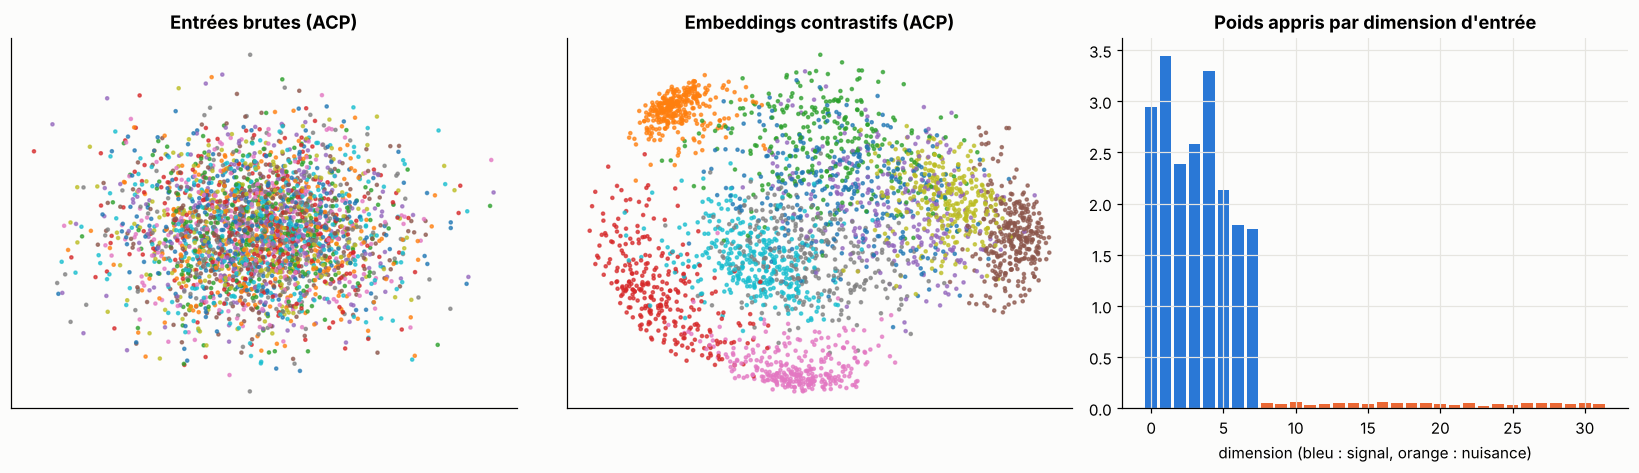

In [5]:
from sklearn.decomposition import PCA
cmap10 = plt.get_cmap("tab10")
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
for ax, (M, title) in zip(axes, [(X_raw, "Entrées brutes (ACP)"), (Z_cl, "Embeddings contrastifs (ACP)"), (None, "")]):
    if M is None:
        continue
    P2 = PCA(2).fit_transform(M)
    ax.scatter(P2[:, 0], P2[:, 1], c=y_lat, cmap=cmap10, s=4, alpha=0.7)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
imp = np.linalg.norm(W_cl, axis=0)
axes[2].bar(range(d_in), imp, color=[PALETTE[0]] * d_sig + [PALETTE[1]] * d_nuis, width=0.8)
axes[2].set_title("Poids appris par dimension d'entrée"); axes[2].set_xlabel("dimension (bleu : signal, orange : nuisance)")
plt.tight_layout(); plt.show()

**Lecture** : dans les entrées brutes, la nuisance domine (l'ACP ne montre qu'un nuage). Après entraînement contrastif, les classes cachées forment des groupes nets, et le graphique des poids montre que l'encodeur a appris à **ignorer les dimensions de nuisance**, uniquement parce qu'elles **changent entre les deux vues** d'un même exemple. Le modèle n'a jamais vu une seule étiquette : toute la « supervision » est dans la définition des positifs.

## 5. La température : sélectionner les négatifs difficiles

### 📐 Le rôle de $\tau$

Le poids qu'un négatif reçoit dans le gradient est $P_{ij}\propto\exp(\mathrm{sim}_{ij}/\tau)$. Plus $\tau$ est **petit**, plus la softmax est piquée (module 0) : seuls les négatifs **les plus proches** de l'ancre (les plus difficiles) comptent. Plus $\tau$ est **grand**, plus tous les négatifs pèsent pareil (Wang & Liu, 2021, « Understanding the Behaviour of Contrastive Loss »).

- $\tau$ trop petit : le modèle se focalise sur quelques négatifs, éventuellement des **faux négatifs** (deux exemples de la même classe tirés dans le batch) qu'il repousse à tort ; entraînement instable.
- $\tau$ trop grand : tous les négatifs sont repoussés uniformément, la structure locale est mal apprise.
- Valeurs typiques : 0,05 (SimCSE), 0,07 (MoCo, CLIP l'apprend en partant de 0,07), 0,1–0,5 (SimCLR).

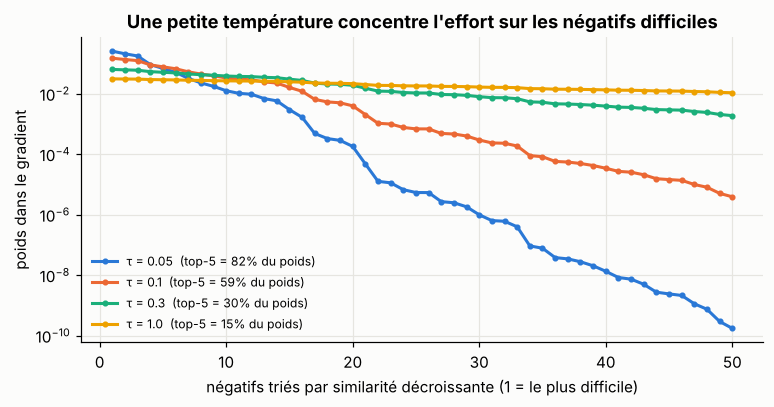

In [6]:
sims = np.sort(rng.uniform(-0.2, 0.9, 50))[::-1]          # cosine similarities of 50 negatives to an anchor
fig, ax = plt.subplots(figsize=(8, 3.6))
for tau, c in zip([0.05, 0.1, 0.3, 1.0], PALETTE):
    w = softmax(sims / tau)
    ax.plot(range(1, 51), w, "o-", ms=3, color=c, label=f"τ = {tau}  (top-5 = {w[:5].sum():.0%} du poids)")
ax.set_xlabel("négatifs triés par similarité décroissante (1 = le plus difficile)"); ax.set_ylabel("poids dans le gradient")
ax.set_yscale("log"); ax.set_title("Une petite température concentre l'effort sur les négatifs difficiles"); ax.legend(fontsize=8)
plt.show()

## 6. Alignement, uniformité et taille du batch

### 📐 Deux propriétés mesurables (Wang & Isola, 2020)

Pour des embeddings normalisés :
$$
\mathcal L_{\text{align}} = \mathbb E_{(x,x^+)}\big[\lVert f(x)-f(x^+)\rVert^2\big],\qquad
\mathcal L_{\text{uniform}} = \log\mathbb E_{x,y}\big[e^{-2\lVert f(x)-f(y)\rVert^2}\big]
$$
- alignement **bas** : les positifs sont proches ;
- uniformité **basse** (très négative) : les points couvrent bien la sphère.

Ils montrent que, quand $N\to\infty$, InfoNCE optimise asymptotiquement exactement ces deux termes. Un encodeur qui envoie tout au même point a un alignement parfait (0) et une uniformité désastreuse : c'est l'**effondrement** (*collapse*), que les négatifs empêchent. (Les méthodes **sans négatifs**, BYOL, SimSiam, VICReg, évitent l'effondrement par d'autres mécanismes : réseau cible à moyenne mobile, *stop-gradient*, régularisation de la variance.)

In [7]:
def align_uniform(W, r=np.random.default_rng(42)):
    Z1, _, _ = encode(W, view(signal, r)); Z2, _, _ = encode(W, view(signal, r))
    align = np.mean(np.sum((Z1 - Z2) ** 2, axis=1))
    sub = Z1[:1000]
    sq = np.sum((sub[:, None] - sub[None]) ** 2, -1)[np.triu_indices(1000, 1)]
    return align, np.log(np.mean(np.exp(-2 * sq)))

rows = []
for tau in [0.03, 0.1, 0.3, 1.0]:
    for batch in [16, 64, 256]:
        W_t, _ = train_contrastive(tau=tau, batch=batch, epochs=15, seed=1)
        a, u = align_uniform(W_t)
        rows.append((tau, batch, a, u, knn_accuracy(encode(W_t, X_raw)[0], y_lat)))
        print(f"tau={tau:<5} batch={batch:<4} align={a:.3f} uniform={u:.3f} kNN acc={rows[-1][4]:.3f}")
rows = np.array(rows)

tau=0.03  batch=16   align=0.181 uniform=-2.093 kNN acc=0.957
tau=0.03  batch=64   align=0.178 uniform=-2.093 kNN acc=0.956
tau=0.03  batch=256  align=0.175 uniform=-2.135 kNN acc=0.958
tau=0.1   batch=16   align=0.255 uniform=-2.465 kNN acc=0.961
tau=0.1   batch=64   align=0.271 uniform=-2.504 kNN acc=0.958
tau=0.1   batch=256  align=0.258 uniform=-2.493 kNN acc=0.963
tau=0.3   batch=16   align=0.298 uniform=-2.597 kNN acc=0.954
tau=0.3   batch=64   align=0.300 uniform=-2.621 kNN acc=0.949
tau=0.3   batch=256  align=0.263 uniform=-2.551 kNN acc=0.957
tau=1.0   batch=16   align=0.223 uniform=-2.348 kNN acc=0.934
tau=1.0   batch=64   align=0.210 uniform=-2.350 kNN acc=0.935
tau=1.0   batch=256  align=0.201 uniform=-2.333 kNN acc=0.937


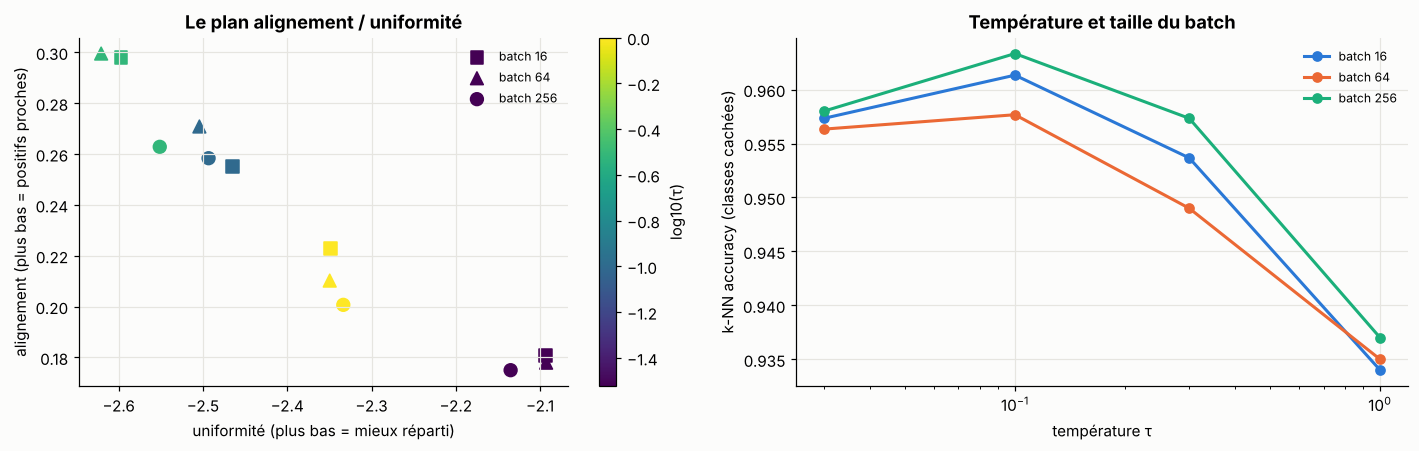

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for b, mk in zip([16, 64, 256], ["s", "^", "o"]):
    sel = rows[:, 1] == b
    sc = axes[0].scatter(rows[sel, 3], rows[sel, 2], c=np.log10(rows[sel, 0]), cmap="viridis", marker=mk, s=70, label=f"batch {b}")
axes[0].set_xlabel("uniformité (plus bas = mieux réparti)"); axes[0].set_ylabel("alignement (plus bas = positifs proches)")
axes[0].set_title("Le plan alignement / uniformité"); axes[0].legend(fontsize=8)
plt.colorbar(sc, ax=axes[0], label="log10(τ)")
for b, c in zip([16, 64, 256], PALETTE):
    sel = rows[:, 1] == b
    axes[1].semilogx(rows[sel, 0], rows[sel, 4], "o-", color=c, label=f"batch {b}")
axes[1].set_xlabel("température τ"); axes[1].set_ylabel("k-NN accuracy (classes cachées)")
axes[1].set_title("Température et taille du batch"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lecture critique** (attention, l'axe de droite est très zoomé : tous les modèles sont entre 93 et 96 %) :
- le plan de gauche montre le **compromis** : une petite température donne le meilleur alignement mais une uniformité médiocre (les points se regroupent trop) ; une température moyenne (0,1–0,3) répartit mieux les points ; une très grande température dégrade les deux et la k-NN accuracy baisse ;
- ici, la **taille du batch** ne change presque rien : avec 10 classes et un encodeur linéaire, quelques négatifs suffisent. Sur des données réelles riches (des millions de phrases ou de séquences), l'effet des grands batchs est au contraire bien documenté (SimCLR, CLIP). Ne généralise jamais un résultat de jouet ;
- $\tau$ et $B$ se règlent sur un jeu de validation, avec la **métrique de la tâche visée** (recherche, STS, k-NN), pas sur la perte contrastive elle-même, qui n'est pas comparable d'un $\tau$ ou d'un $B$ à l'autre.

## 7. SimCSE : des embeddings de phrases par contraste

Au module 7, on a vu que la moyenne des états d'un BERT pré-entraîné donne des embeddings de phrases **anisotropes** (tout dans un cône étroit) et médiocres pour la similarité. SimCSE (Gao, Yao & Chen, 2021) corrige cela par un apprentissage contrastif minimaliste :

- **non supervisé** : on passe **deux fois** la même phrase dans l'encodeur, en mode entraînement. Le **dropout** est différent à chaque passe : on obtient deux vues légèrement différentes, qui sont les positifs. Les autres phrases du batch sont les négatifs. Aucune autre augmentation (supprimer ou remplacer des mots dégradait les résultats) ;
- **supervisé** : positifs = paires d'**implication** issues de jeux NLI, et **négatif difficile** = la phrase en **contradiction**, ajoutée aux négatifs du batch.

Effet mesuré par les auteurs : l'uniformité s'améliore fortement (l'anisotropie disparaît) sans trop dégrader l'alignement.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModel, AutoTokenizer

device = "cuda" if torch.cuda.is_available() else "cpu"
name = "camembert-base"
tok = AutoTokenizer.from_pretrained(name)
encoder = AutoModel.from_pretrained(name).to(device)


def embed(batch_texts, model):
    enc = tok(batch_texts, padding=True, truncation=True, max_length=64, return_tensors="pt").to(device)
    h = model(**enc).last_hidden_state
    return h[:, 0]                                    # SimCSE uses the [CLS]/<s> vector (+ an MLP head during training)


def simcse_unsup_loss(texts, model, tau=0.05):
    z1 = F.normalize(embed(texts, model), dim=-1)     # model.train(): dropout ON
    z2 = F.normalize(embed(texts, model), dim=-1)     # same texts, different dropout mask -> positives
    sim = z1 @ z2.T / tau                              # (B, B)
    labels = torch.arange(len(texts), device=device)
    return F.cross_entropy(sim, labels)                # InfoNCE with in-batch negatives


def simcse_sup_loss(anchors, positives, hard_negatives, model, tau=0.05):
    za = F.normalize(embed(anchors, model), dim=-1)
    zc = F.normalize(embed(positives + hard_negatives, model), dim=-1)   # (2B, d): B positives then B hard negatives
    sim = za @ zc.T / tau                                               # each anchor vs all positives AND all hard negatives
    return F.cross_entropy(sim, torch.arange(len(anchors), device=device))


# Toy training loop (use a large unlabeled corpus of sentences from your domain in practice)
sentences = ["Le film était excellent.", "Quelle déception, ce restaurant.", "La protéine se replie rapidement.",
             "Le service était lent mais aimable.", "Ce livre m'a ému aux larmes.", "Les anticorps reconnaissent l'antigène."] * 20
opt = torch.optim.AdamW(encoder.parameters(), lr=3e-5)
encoder.train()
for step in range(0, len(sentences), 32):
    loss = simcse_unsup_loss(sentences[step:step + 32], encoder)
    opt.zero_grad(); loss.backward(); opt.step()
    print(f"step {step // 32} | loss {loss.item():.3f} (log B = {np.log(len(sentences[step:step + 32])):.2f})")

> ⚠️ **Piège des doublons** : si la même phrase apparaît deux fois dans un batch (comme dans l'exemple jouet ci-dessus, volontairement répété), elle est à la fois positif et **faux négatif** d'elle-même. Dédupliquer les batchs ; c'est encore plus important pour des séquences biologiques redondantes (section 9).

## 8. `sentence-transformers`, négatifs difficiles et évaluation

La librairie `sentence-transformers` implémente tout cela proprement. La perte `MultipleNegativesRankingLoss` **est** InfoNCE avec négatifs dans le batch (et négatifs difficiles optionnels en 3e colonne).

In [ ]:
from sentence_transformers import SentenceTransformer, InputExample, losses
from torch.utils.data import DataLoader

st_model = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
train_examples = [
    InputExample(texts=["Le film était excellent.", "J'ai adoré ce film.", "Le film était nul."]),   # anchor, positive, hard negative
    InputExample(texts=["La protéine est stable à 37 °C.", "Elle reste repliée à température corporelle.", "Elle se dénature à 37 °C."]),
]
loader = DataLoader(train_examples, shuffle=True, batch_size=2)
loss_fn = losses.MultipleNegativesRankingLoss(st_model, scale=20.0)     # scale = 1 / tau  (tau = 0.05)
st_model.fit(train_objectives=[(loader, loss_fn)], epochs=1, warmup_steps=0, show_progress_bar=False)

emb = st_model.encode(["Le chat dort.", "Un félin fait la sieste.", "La bourse a chuté."], normalize_embeddings=True)
print(np.round(emb @ emb.T, 2))

### Les négatifs difficiles

Les négatifs aléatoires deviennent vite **trop faciles** (gradient quasi nul, section 5). On ajoute des négatifs **difficiles** : proches de l'ancre mais pas positifs. Sources :
- un système lexical (BM25) qui trouve des passages similaires mais non pertinents (DPR) ;
- le modèle lui-même : on encode le corpus, on prend les plus proches voisins non positifs (*hard negative mining*), on réentraîne, on recommence ;
- des étiquettes : contradictions NLI (SimCSE supervisé).

**Le danger des faux négatifs** : un « négatif difficile » est souvent un positif non annoté. Filtrer ceux dont la similarité dépasse un seuil, ou utiliser un modèle plus puissant (*cross-encoder*) pour les vérifier.

### Évaluer des embeddings

| Usage | Métrique |
|---|---|
| similarité sémantique (STS) | corrélation de **Spearman** entre cosinus et scores humains |
| recherche | **Recall@k**, MRR, nDCG |
| regroupement | V-mesure, ARI contre des classes connues |
| transfert | **sonde linéaire** (*linear probe*) ou k-NN sur une tâche supervisée |

In [9]:
def recall_at_k(Q, D, k=(1, 5, 10)):
    """Q[i] should retrieve D[i]."""
    Qn, Dn = Q / np.linalg.norm(Q, axis=1, keepdims=True), D / np.linalg.norm(D, axis=1, keepdims=True)
    ranks = np.argsort(-(Qn @ Dn.T), axis=1)
    pos = np.array([np.where(ranks[i] == i)[0][0] for i in range(len(Q))])
    return {f"R@{kk}": float(np.mean(pos < kk)) for kk in k} | {"MRR": float(np.mean(1 / (pos + 1)))}

r_eval = np.random.default_rng(7)
idx = r_eval.choice(n, 500, replace=False)
V1, V2 = view(signal[idx], r_eval), view(signal[idx], r_eval)
print("retrieve the other view of the same example among 500 candidates")
print("  raw inputs  :", {k: round(v, 3) for k, v in recall_at_k(V1, V2).items()})
print("  contrastive :", {k: round(v, 3) for k, v in recall_at_k(encode(W_cl, V1)[0], encode(W_cl, V2)[0]).items()})

retrieve the other view of the same example among 500 candidates
  raw inputs  : {'R@1': 0.008, 'R@5': 0.026, 'R@10': 0.048, 'MRR': 0.028}
  contrastive : {'R@1': 0.43, 'R@5': 0.624, 'R@10': 0.702, 'MRR': 0.527}


## 9. En biologie : séquences, paires et modalités

L'apprentissage contrastif est très utilisé avec les modèles de protéines, et le **choix des positifs** y encode la question biologique :

| Positifs | Ce qu'on apprend | Piège principal |
|---|---|---|
| deux séquences d'une même famille / d'un même cluster | un espace où la proximité reflète l'homologie | si les clusters sont trop larges, des fonctions différentes deviennent « positives » |
| séquence et sa description textuelle (fonction, annotation) | un espace partagé séquence–texte, à la CLIP, permettant la recherche par requête textuelle | annotations bruitées ou héritées par homologie |
| séquence et structure | une représentation sensible au repliement | |
| chaînes lourde et légère **appariées** d'un même anticorps | la compatibilité d'appariement | la plupart des données d'anticorps ne sont **pas** appariées |
| deux vues d'une séquence (masquage, mutations aléatoires) | robustesse, à la SimCLR | une mutation aléatoire peut changer la fonction : les vues ne sont pas forcément « équivalentes » |

**Les faux négatifs** sont le problème central : dans un batch tiré au hasard d'une base protéique, deux séquences **homologues** peuvent se retrouver ancre et « négatif ». Parades : échantillonner un seul représentant par cluster dans chaque batch (comme ESM échantillonne UniRef50), ou retirer de la softmax les négatifs trop similaires à l'ancre (au-dessus d'un seuil d'identité ou de similarité).

**Et pour l'évaluation**, toutes les règles du module 8 s'appliquent : un Recall@k mesuré avec des homologues du jeu d'entraînement dans la base de recherche est optimiste. Rapporte les scores en fonction de l'identité maximale aux séquences d'entraînement.

## 10. Récapitulatif

| Notion | À retenir |
|---|---|
| Principe | rapprocher les positifs, éloigner les négatifs ; les positifs définissent les invariances |
| InfoNCE | softmax CE sur $S = ZZ'^\top/\tau$, bonne classe = diagonale ; symétrique (CLIP) |
| Gradient | attraction vers le positif, répulsion pondérée par $P_{ij}$ ; projection tangente si $z$ normalisé |
| Information mutuelle | $I \ge \log N - \mathcal L$ ; plus de négatifs = borne plus haute |
| Température | petite = focalisée sur les négatifs difficiles (et les faux négatifs) ; 0,05–0,1 typique |
| Géométrie | alignement + uniformité ; effondrement sans négatifs |
| SimCSE | dropout comme augmentation ; NLI pour la version supervisée |
| Négatifs difficiles | BM25, minage par le modèle, contradictions ; filtrer les faux négatifs |
| Évaluation | Spearman (STS), Recall@k / MRR, sonde linéaire, k-NN |
| Biologie | positifs = homologues, paires, texte ; échantillonnage par cluster contre les faux négatifs |

### 🏋️ Exercices

1. **Effondrement.** Remplace la perte par le seul terme d'alignement $\lVert z_1 - z_2\rVert^2$. Que deviennent l'uniformité et la k-NN accuracy ? Ajoute un terme d'uniformité pondéré (Wang & Isola) et compare à InfoNCE.
2. **Faux négatifs.** Dans `info_nce_grads`, retire de la softmax les paires $(i, j)$, $i\ne j$, qui partagent la même classe cachée (version « supervisée », SupCon). Le gain est-il important ? Que dit-il du coût des faux négatifs ?
3. **Mauvaises augmentations.** Fais aussi varier une dimension de **signal** entre les deux vues. Que devient le poids appris pour cette dimension ? Conclusion sur le choix des augmentations ?
4. **Température apprise.** Fais de $\log(1/\tau)$ un paramètre appris (comme CLIP) et dérive son gradient. Vers quelle valeur converge-t-il ?
5. **SimCSE en vrai.** Entraîne SimCSE non supervisé sur 10 000 phrases de ton domaine et mesure l'anisotropie (cosinus moyen entre phrases aléatoires) avant / après.

<details><summary>Indications</summary>

1. Sans négatifs, tout s'effondre vers un point : alignement parfait, uniformité nulle, k-NN au hasard.
2. SupCon (Khosla et al., 2020) généralise InfoNCE à plusieurs positifs par ancre ; avec 10 classes et des batchs de 256, ~10 % des « négatifs » sont faux.
3. Le modèle apprend à ignorer **tout** ce qui varie entre les vues : une augmentation qui modifie l'information utile la détruit.
4. $\partial\mathcal L/\partial s = \sum_{ij}(P_{ij} - \mathbb 1[i=j])\,\mathrm{cos}_{ij}$ pour $s = 1/\tau$ (à moyenner) ; CLIP borne $1/\tau \le 100$ pour la stabilité.
</details>

**➡️ Module suivant : la distillation de connaissances** (transférer un grand modèle « professeur » dans un petit « élève » : cibles douces, température, DistilBERT, TinyBERT).